# 2. Downscaling: placing the MODIS snow fraction at 30 m

For each day, MODIS says **how much** of each 463 m pixel is snow covered. The snow-persistence ranking from notebook 1 says **where** within the pixel that snow most likely is. The downscaling fills each neighbourhood with snow in rank order until the MODIS fraction is used up.

This notebook does that for the example day (18 March 2019), compares the result with the Landsat snow map of the same day, and then turns one cell's daily series into snow-on and snow-off dates. Production scripts: `downscale.py` (the method), `ds_run.py` (all days) and `build_essd_nc.py` (the released NetCDF files).

*Disclosure: the processing code and these notebooks were written with the assistance of Claude (Anthropic), working under the direction of the authors.*

In [1]:
import os, sys, io, tarfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4

ROOT = Path("..")                      # essd_draft/
CODE = ROOT / "code"
DATA = Path("data"); DATA.mkdir(exist_ok=True)
os.environ["SNOW_DOMAIN"] = "rcew"     # the pipeline code reads the domain from this variable
sys.path.insert(0, str(CODE))

SEASONS_NC = ROOT / "rcew_snow_seasons_30m_v1.nc"
DAILY_STEM = "rcew_snowcover_daily_30m_v1"   # one file, or parts along time (see daily_io.py)
MODIS_TAR = ROOT / "inputs" / "rcew_mod10a1f_window_2000_2026.tar"
EXAMPLE_DATE = pd.Timestamp("2019-03-18")   # clear Landsat 8 overpass with a partly snow-covered watershed

plt.rcParams.update({"font.size": 9, "figure.dpi": 110, "axes.facecolor": "#d4d4d4"})   # grey = outside or no data
from matplotlib.colors import LinearSegmentedColormap
SNOW = LinearSegmentedColormap.from_list("snow", ["#5c4326", "#9c7a4e", "#cdbb98", "#e6e9ea", "#ffffff"])   # bare ground to snow

In [2]:
S = netCDF4.Dataset(SEASONS_NC)
grab = lambda k: np.ma.filled(S[k][:].astype(float), np.nan)
x, y = S["x"][:], S["y"][:]
region = np.ma.filled(S["region"][:], 0).astype(int)
inside = region > 0
elev, slope, aspect = grab("elevation"), grab("slope"), grab("aspect")
forest = np.ma.filled(S["forest"][:], 0).astype(bool)
persistence = grab("snow_persistence")
extent = [x.min() - 15, x.max() + 15, y.min() - 15, y.max() + 15]
NY, NX = region.shape
print(f"grid {NY} x {NX} cells at 30 m, {inside.sum() * 900 / 1e6:.0f} km2 inside the watershed, "
      f"{np.nanmin(elev):.0f}-{np.nanmax(elev):.0f} m, forest share {forest[inside].mean():.0%}")

grid 1030 x 560 cells at 30 m, 240 km2 inside the watershed, 1104-2241 m, forest share 15%


In [3]:
def modis_day(date):
    """One day's MOD10A1F window (89 x 179 pixels at 463 m) from the archive of pre-cut windows."""
    name = f"mod/A{date.year}{date.dayofyear:03d}.npz"
    with tarfile.open(MODIS_TAR) as t:
        return dict(np.load(io.BytesIO(t.extractfile(name).read())))

## 2.1 Set up the terrain object

`Terrain` holds, for every 30 m cell, its position inside the MODIS grid and the terrain quantities used for ranking. It is built here from the static layers of the released seasons file (the same route as `rebuild_inputs_from_nc.py`). The first call compiles a few functions and takes about a minute.

In [4]:
from downscale import Terrain, ndsi_to_fsca

G = dict(region=region, elev=elev, slope=slope, aspect=aspect, lon=grab("lon"), lat=grab("lat"))
T = Terrain(G)
T.set_persistence(persistence, "all"); T.emp_fold = "all"
print("cells ranked:", T.valid.sum())

cells ranked: 266376


## 2.2 One day, step by step

1. **MODIS fSCA** at 463 m (notebook 1).
2. **Interpolate** fSCA bilinearly between MODIS pixel centres to every 30 m cell. Ranking inside whole MODIS pixels would leave visible seams along pixel edges; interpolating removes them.
3. **Rank** each cell by snow persistence within a 15 x 15 cell (450 m) window centred on it, as a percentile from 0 (holds snow longest) to 1.
4. A cell is **snow covered** when its percentile is at or below its interpolated fSCA.

snow on 37% of cells; mean interpolated fSCA 37%


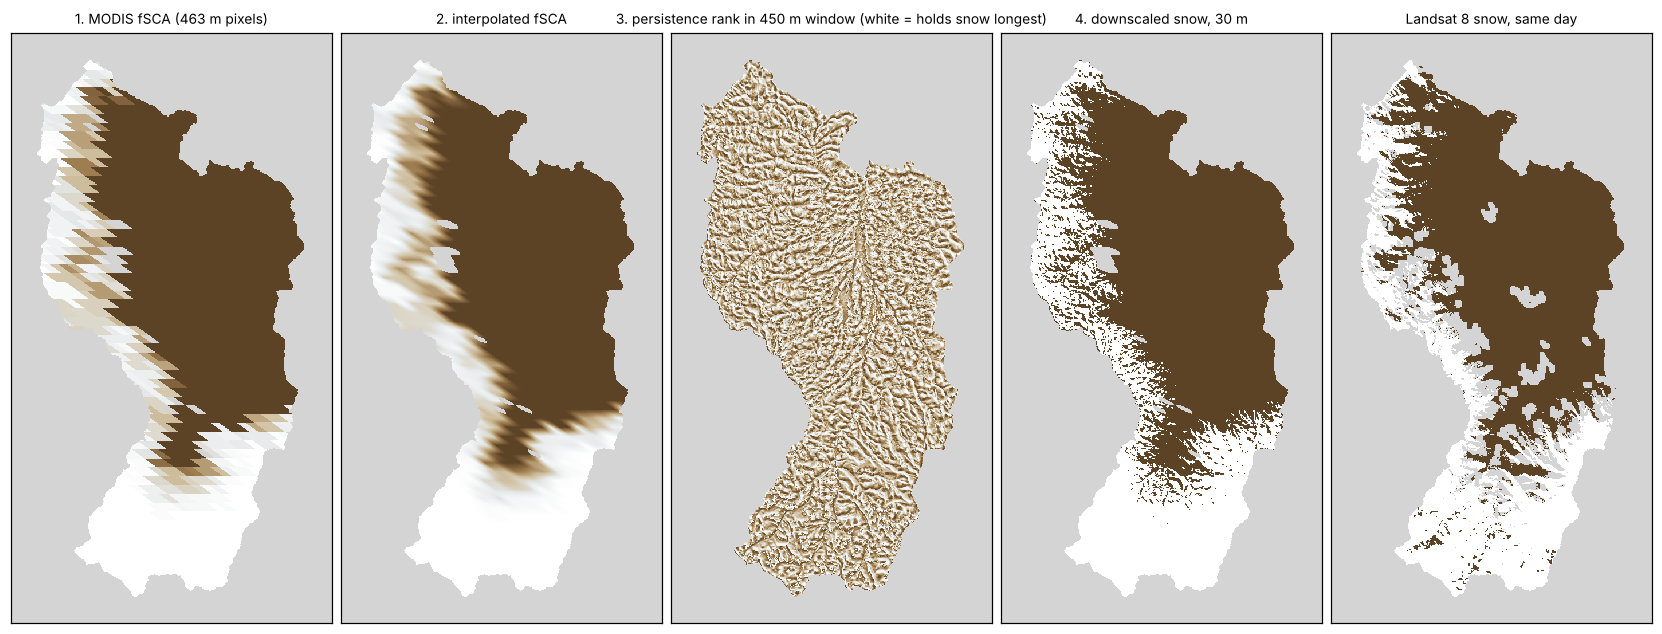

In [5]:
m = modis_day(EXAMPLE_DATE)
ndsi = m["CGF_NDSI_Snow_Cover"].astype(float)
fsca_modis = np.where((ndsi <= 100) & (m["Cloud_Persistence"] <= 10), ndsi_to_fsca(ndsi), np.nan)

fsca30 = T.fsca_field(fsca_modis, "emp_smooth")          # step 2
rank = T.prank(EXAMPLE_DATE.dayofyear, 0, "emp_smooth")   # step 3 (the same for every day)
snow30, ok = T.snow(rank, fsca30)                         # step 4
ok &= inside
print(f"snow on {snow30[ok].mean():.0%} of cells; mean interpolated fSCA {np.nanmean(fsca30[ok]):.0%}")

landsat = np.load(DATA / "example_landsat_snow_20190318.npz")["snow"]
fsca_block = T.fsca_field(fsca_modis, "block")
panels = [(np.where(inside, fsca_block, np.nan), "1. MODIS fSCA (463 m pixels)"),
          (np.where(inside, fsca30, np.nan), "2. interpolated fSCA"),
          (np.where(inside, 1 - rank, np.nan), "3. persistence rank in 450 m window (white = holds snow longest)"),
          (np.where(ok, snow30.astype(float), np.nan), "4. downscaled snow, 30 m"),
          (np.where(inside & (landsat < 255), landsat.astype(float), np.nan), "Landsat 8 snow, same day")]
fig, axs = plt.subplots(1, 5, figsize=(15, 5.6), constrained_layout=True)
for ax, (fld, title) in zip(axs, panels):
    ax.imshow(fld, extent=extent, cmap=SNOW, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 2.3 Does the ranking matter?

Score the downscaled map against the Landsat map with the F-measure (2TP / (2TP + FP + FN)) on cells that Landsat saw clearly. The score is restricted to cells whose interpolated fSCA lies between 5% and 95%, because where MODIS says "all snow" or "no snow" every ranking gives the same answer.

Three rankings are compared with the same fSCA:

- **snow persistence** (the product);
- a **terrain score** in the style of Walters et al. (2014): 0.5 x insolation + 0.5 x relative elevation;
- a **random** order, which shows what MODIS alone gives.

One caveat for this single-day example: the persistence layer was built from all scenes, including this one. The published skill uses persistence from the other half of the years (odd versus even water years); that table is in notebook 3.

In [6]:
def f_measure(pred, ref, sel):
    tp = (pred & ref & sel).sum(); fp = (pred & ~ref & sel).sum(); fn = (~pred & ref & sel).sum()
    return 2 * tp / (2 * tp + fp + fn)

from downscale import window_prank, WIN
ref = landsat == 1
partial = ok & (landsat < 255) & (fsca30 > 0.05) & (fsca30 < 0.95)
rng = np.random.default_rng(0)
ranks = {"snow persistence": rank,
         "terrain score": T.prank(EXAMPLE_DATE.dayofyear, 0.5, "smooth"),
         "random": window_prank(np.where(T.valid, rng.random(rank.shape), 0.0), T.valid, WIN)}
rows = []
for name, r in ranks.items():
    pred, _ = T.snow(r, fsca30)
    rows.append(dict(ranking=name, F_all=f_measure(pred, ref, partial), F_open=f_measure(pred, ref, partial & ~forest),
                     F_forest=f_measure(pred, ref, partial & forest)))
print(f"{partial.sum():,} cells in partly snow-covered neighbourhoods ({partial.sum() / ok.sum():.0%} of the watershed)")
pd.DataFrame(rows).set_index("ranking").round(3)

62,142 cells in partly snow-covered neighbourhoods (24% of the watershed)


,F_all,F_open,F_forest
ranking,,,
snow persistence,0.872,0.873,0.864
terrain score,0.811,0.801,0.882
random,0.728,0.712,0.844


## 2.4 Why interpolate? Pixel seams

Filling each MODIS pixel separately ("block", as in the original method) leaves straight edges where neighbouring pixels have different snow fractions. A zoom on the snow line shows the difference.

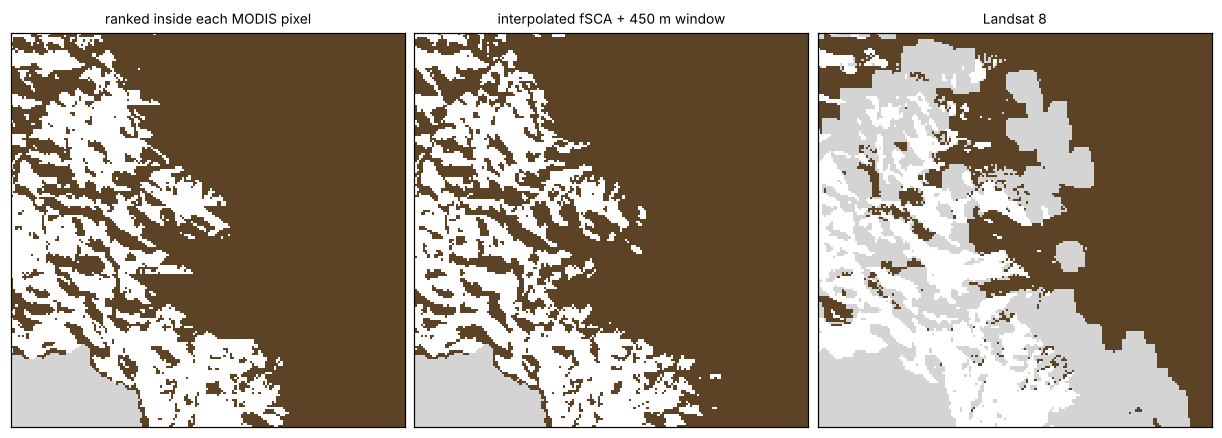

In [7]:
snow_block, _ = T.snow(T.prank(EXAMPLE_DATE.dayofyear, 0, "emp_block"), fsca_block)
iy0, ix0 = [int(v) for v in np.argwhere(inside & (fsca30 > 0.3) & (fsca30 < 0.7))[len(np.argwhere(inside & (fsca30 > 0.3) & (fsca30 < 0.7))) // 2]]
win = (slice(max(iy0 - 90, 0), iy0 + 90), slice(max(ix0 - 90, 0), ix0 + 90))
fig, axs = plt.subplots(1, 3, figsize=(11, 3.9), constrained_layout=True)
for ax, fld, title in [(axs[0], snow_block, "ranked inside each MODIS pixel"), (axs[1], snow30, "interpolated fSCA + 450 m window"),
                       (axs[2], np.where(landsat == 255, np.nan, landsat), "Landsat 8")]:
    ax.imshow(np.where(inside[win], np.asarray(fld, float)[win], np.nan), cmap=SNOW, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 2.5 From daily maps to snow-on and snow-off dates

`ds_run.py` repeats step 2.2 for all 9,716 days and `build_essd_nc.py` writes the daily file with its quality flags. Per cell and water year, the season rules (`ondates.py`) are:

- a missing day is filled when the days before and after agree;
- snow-free gaps of up to 3 days inside snow cover are bridged;
- the **main season** is the longest continuous run of at least 14 days; `snow_on` is its first day and `snow_off` (melt-out) the first snow-free day after it.

Below, one cell's daily series for water year 2019, read from the released daily file.

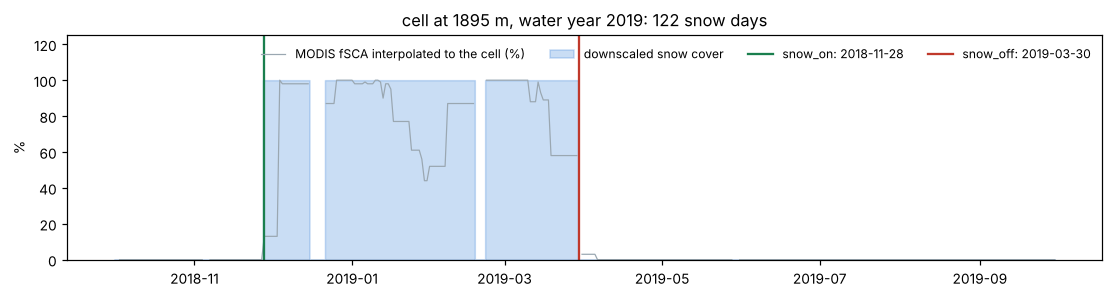

melt-out from this notebook: day 181 of the water year; stored in the seasons file: day 181


In [8]:
from ondates import season
from daily_io import Daily

D = Daily(ROOT, DAILY_STEM)
iy, ix = [int(v) for v in np.argwhere(inside & (np.abs(elev - 1900) < 5) & ~forest)[0]]
days = pd.date_range("2018-10-01", "2019-09-30")
sc = D.cell("snow_cover", iy, ix, days[0], days[-1]).reindex(days).values
fs = D.cell("input_fsca", iy, ix, days[0], days[-1]).reindex(days).values
s = season(sc)
t = days
fig, ax = plt.subplots(figsize=(10, 2.6), constrained_layout=True); ax.set_facecolor("white")
ax.plot(t, fs, color="#9aa7b1", lw=0.8, label="MODIS fSCA interpolated to the cell (%)")
ax.fill_between(t, 0, np.where(sc == 1, 100, 0), step="mid", color="#2a78d6", alpha=0.25, label="downscaled snow cover")
for key, col in [("snow_on", "#1a7f4e"), ("snow_off", "#c0392b")]:
    ax.axvline(t[int(s[key])], color=col, lw=1.5, label=f"{key}: {t[int(s[key])].date()}")
ax.set_ylabel("%"); ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper right"); ax.set_ylim(0, 125)
ax.set_title(f"cell at {elev[iy, ix]:.0f} m, water year 2019: {int(s['scd'])} snow days")
plt.show()

stored = int(S["snow_off"][list(S["water_year"][:]).index(2019), iy, ix])
print("melt-out from this notebook: day", int(s["snow_off"]) + 1, "of the water year; stored in the seasons file: day", stored)

**Outputs of this step:** `rcew_snowcover_daily_30m_v1.nc` (daily snow cover, input fSCA, cloud age and quality flags) and `rcew_snow_seasons_30m_v1.nc` (snow-on, snow-off and snow-cover days per water year). Notebook 3 checks them against independent data.